# 06 — Results Summary and Visual Story

This notebook turns the technical outputs from Notebooks 1–5 into thesis-ready tables, figures, and interpretation text.

## Main purpose

This is **not** another modeling notebook.

It is a communication notebook. Its job is to make the thesis results simple for the audience.

## Core message

The thesis is not mainly about prediction.

The thesis is about building a **plot/story-based film network**:

```text
film plot descriptions
→ NLP embeddings
→ semantic similarity
→ mutual-KNN network
→ narrative communities
→ central and bridging story positions
→ relationship with multiple success signals
```

## Output style

The final results should be understandable to someone who does not know graph theory:

- A **node** is a movie.
- An **edge** is story similarity.
- A **community** is a group of movies with similar plot patterns.
- A **central movie** is a typical example of a narrative neighborhood.
- A **bridging movie** connects different narrative neighborhoods.
- Success is treated as multi-dimensional: commercial, audience attention, and evaluative reception.


## 1. Imports

In [3]:
import os
import re
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 160)

print("Imports ready.")

Imports ready.


## 2. Project paths

Set `PROJECT_DIR` to your main project folder.

This notebook reads existing outputs and creates final presentation tables/figures.


In [4]:
# In Colab, uncomment if needed.
# This safer mount logic avoids errors if Drive is already mounted.
try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
OUTPUT_FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
FINAL_TABLES_DIR = OUTPUT_TABLES_DIR / "final_story_tables"
FINAL_FIGURES_DIR = OUTPUT_FIGURES_DIR / "final_story_figures"

for d in [FINAL_TABLES_DIR, FINAL_FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_TABLES_DIR:", FINAL_TABLES_DIR)
print("FINAL_FIGURES_DIR:", FINAL_FIGURES_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_TABLES_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables
FINAL_FIGURES_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/figures/final_story_figures


## 3. Input files

In [5]:
files = {
    # Network and interpretation
    "network_basic_checks": OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "major_community_table": OUTPUT_TABLES_DIR / "major_community_thesis_table.csv",
    "top_visible_central": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "top_betweenness_visible": OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",
    "community_success_summary": OUTPUT_TABLES_DIR / "community_success_summary.csv",

    # Notebook 5 outputs
    "modeling_audit": OUTPUT_TABLES_DIR / "modeling_sample_audit.csv",
    "key_coefficients": OUTPUT_TABLES_DIR / "regression_key_coefficients_summary.csv",
    "reg_log_revenue": OUTPUT_TABLES_DIR / "regression_results_log_revenue.csv",
    "reg_revenue_pct": OUTPUT_TABLES_DIR / "regression_results_revenue_percentile.csv",
    "reg_vote_average": OUTPUT_TABLES_DIR / "regression_results_vote_average.csv",
    "reg_popularity": OUTPUT_TABLES_DIR / "regression_results_popularity.csv",
    "modeling_table": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
}

for name, path in files.items():
    print(f"{name:28s}", path.exists(), "-", path)

missing = [name for name, path in files.items() if not path.exists()]
if missing:
    print("\nMissing files:")
    for name in missing:
        print("-", name, files[name])
    raise FileNotFoundError("Some required files are missing. Run Notebooks 4 and 5 first.")

network_basic_checks         True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_interpretation_basic_checks.csv
community_labels             True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
major_community_table        True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/major_community_thesis_table.csv
top_visible_central          True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
top_betweenness_visible      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_betweenness_visible_franchise_capped.csv
community_success_summary    True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_success_summary.csv
modeling_audit               True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/modeling_sample_audit.csv
key_coefficients             True - /content/drive/MyDrive/thesis_movi

## 4. Load data

In [6]:
network_basic = pd.read_csv(files["network_basic_checks"])
community_labels = pd.read_csv(files["community_labels"])
major_communities = pd.read_csv(files["major_community_table"])
top_visible_central = pd.read_csv(files["top_visible_central"])
top_betweenness_visible = pd.read_csv(files["top_betweenness_visible"])
community_success = pd.read_csv(files["community_success_summary"])
modeling_audit = pd.read_csv(files["modeling_audit"])
key_coef = pd.read_csv(files["key_coefficients"])

reg_files = {
    "log_revenue": files["reg_log_revenue"],
    "revenue_percentile_year": files["reg_revenue_pct"],
    "vote_average": files["reg_vote_average"],
    "log_popularity": files["reg_popularity"],
}

regression_results = []
for outcome, path in reg_files.items():
    temp = pd.read_csv(path)
    temp["outcome_file"] = outcome
    regression_results.append(temp)

regression_results = pd.concat(regression_results, ignore_index=True)

modeling_table = pd.read_csv(files["modeling_table"])

print("network_basic:", network_basic.shape)
print("community_labels:", community_labels.shape)
print("major_communities:", major_communities.shape)
print("top_visible_central:", top_visible_central.shape)
print("top_betweenness_visible:", top_betweenness_visible.shape)
print("community_success:", community_success.shape)
print("modeling_audit:", modeling_audit.shape)
print("regression_results:", regression_results.shape)
print("modeling_table:", modeling_table.shape)

display(network_basic)
display(community_labels.head(5))

network_basic: (8, 2)
community_labels: (23, 15)
major_communities: (23, 7)
top_visible_central: (77, 12)
top_betweenness_visible: (50, 12)
community_success: (26, 14)
modeling_audit: (10, 2)
regression_results: (388, 11)
modeling_table: (19202, 61)


,check,value
0,n_nodes,19202.00
1,n_edges,86685.00
2,n_communities,26.00
3,min_year,1990.00
4,max_year,2024.00
5,median_vote_count,95.00
6,median_overview_word_count,56.50
7,revenue_available_pct,39.45


,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.1,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023); The Bachelors (2017); The Harbinger (20...,Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way of Water (2022); Life Is Beautiful (199...,"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grief, or life-transition elements. Because ..."
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.3,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Dating Santa (2023); Ex 2: Still Friends (...",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Paris (1999); The Sicilian Girl (2008),Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pan's Labyrinth (2006); (500) Days of Summ...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, family bonds, and comedy-drama plots. The pre..."
2,3,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),1990-2024,2013.0,61.0,6.6,34.15,"Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008); Ring 2 (1999); My Tomorrow, Your Yest...","Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yoko (2012)",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); The Last Samurai (2003); Manchester by th...,Japanese/Korean action-animation and cross-cultural personal drama,"This neighborhood is strongly shaped by Japanese and Korean titles, anime-linked stories, and action-drama plots with personal or familial stakes. It should..."
3,4,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),1990-2024,2012.0,102.0,6.0,41.11,Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020); Headwinds (2011); In Their Sleep (2010),Die In One Day (2017); Animal Kingdom (2010); Agent Cody Banks (2003); Hope Springs (2003); Rose (2012); The Attic Expeditions (2001),Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Curious Case of Benjamin Button (2008); Gr...,"Coming-of-age, identity, and character-centered social drama","This community appears to emphasize identity formation, emotional growth, and socially grounded character arcs, often with coming-of-age or interpersonal co..."
4,5,24,1327,6.91,Drama (503); Comedy (409); Horror (67); Thriller (63); Romance (61); Crime (49),1990-2024,2014.0,99.0,6.1,34.97,What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); Everybody Loves Jeanne (2022); Hear Me O...,The Sweet Life (2017); Stormskerry Maja (2024); Soul Mates (2023); Adaptation. (2002); The Minister (2011); By the Grace of God (2019),Up (2009); Kill Bill: Vo

## 5. Final network summary table

This table explains the network in plain language.

Use it in the thesis/results chapter.


In [7]:
def lookup_metric(df, key, default=np.nan):
    if "check" in df.columns:
        hit = df.loc[df["check"] == key, "value"]
    elif "metric" in df.columns:
        hit = df.loc[df["metric"] == key, "value"]
    else:
        return default
    if len(hit) == 0:
        return default
    return hit.iloc[0]

n_nodes = int(float(lookup_metric(network_basic, "n_nodes")))
n_edges = int(float(lookup_metric(network_basic, "n_edges")))
n_communities = int(float(lookup_metric(network_basic, "n_communities")))
min_year = int(float(lookup_metric(network_basic, "min_year")))
max_year = int(float(lookup_metric(network_basic, "max_year")))
median_vote_count = float(lookup_metric(network_basic, "median_vote_count"))
median_overview_words = float(lookup_metric(network_basic, "median_overview_word_count"))
revenue_pct = float(lookup_metric(network_basic, "revenue_available_pct"))

n_major_communities = community_labels.shape[0]

final_network_summary = pd.DataFrame([
    {
        "result_element": "Films in final plot-similarity network",
        "value": f"{n_nodes:,}",
        "audience_meaning": "These are the movies in the largest connected component of the semantic network."
    },
    {
        "result_element": "Story-similarity links",
        "value": f"{n_edges:,}",
        "audience_meaning": "Each link connects two movies with similar plot descriptions."
    },
    {
        "result_element": "Total detected communities",
        "value": f"{n_communities:,}",
        "audience_meaning": "These are story neighborhoods discovered from the network."
    },
    {
        "result_element": "Major interpreted communities",
        "value": f"{n_major_communities:,}",
        "audience_meaning": "These are the larger communities manually labeled for thesis interpretation."
    },
    {
        "result_element": "Release-year range",
        "value": f"{min_year}–{max_year}",
        "audience_meaning": "The main film period covered by the final network."
    },
    {
        "result_element": "Median vote count",
        "value": f"{median_vote_count:.0f}",
        "audience_meaning": "The typical network film has a non-trivial audience signal."
    },
    {
        "result_element": "Median plot length",
        "value": f"{median_overview_words:.1f} words",
        "audience_meaning": "Plot texts are short but usually informative enough for semantic comparison."
    },
    {
        "result_element": "Revenue availability",
        "value": f"{revenue_pct:.2f}%",
        "audience_meaning": "Commercial-success analysis is conducted on the revenue-available subset."
    },
])

display(final_network_summary)

final_network_summary.to_csv(
    FINAL_TABLES_DIR / "final_network_summary_table.csv",
    index=False
)

print("Saved:", FINAL_TABLES_DIR / "final_network_summary_table.csv")

,result_element,value,audience_meaning
0,Films in final plot-similarity network,"19,202",These are the movies in the largest connected component of the semantic network.
1,Story-similarity links,"86,685",Each link connects two movies with similar plot descriptions.
2,Total detected communities,26,These are story neighborhoods discovered from the network.
3,Major interpreted communities,23,These are the larger communities manually labeled for thesis interpretation.
4,Release-year range,1990–2024,The main film period covered by the final network.
5,Median vote count,95,The typical network film has a non-trivial audience signal.
6,Median plot length,56.5 words,Plot texts are short but usually informative enough for semantic comparison.
7,Revenue availability,39.45%,Commercial-success analysis is conducted on the revenue-available subset.


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_network_summary_table.csv


## 6. Success dimensions table

This table reframes success as multi-dimensional.

The thesis should not treat success as only box office.


In [8]:
final_success_dimensions = pd.DataFrame([
    {
        "success_dimension": "Commercial success",
        "variables_used": "log_revenue; revenue_percentile_year",
        "meaning": "Financial market performance.",
        "limitation": "Revenue is missing for many films and is affected by distribution, release scale, marketing, inflation, and territory coverage."
    },
    {
        "success_dimension": "Audience attention / fan visibility",
        "variables_used": "vote_count; popularity; log_popularity",
        "meaning": "How much attention or engagement a movie receives on the platform.",
        "limitation": "Platform-dependent and not a pure measure of long-term fan culture."
    },
    {
        "success_dimension": "Evaluative reception",
        "variables_used": "vote_average",
        "meaning": "Rating-based reception from users/audiences.",
        "limitation": "Can be biased by who votes, vote volume, platform demographics, and time."
    },
    {
        "success_dimension": "Recognition / awards success",
        "variables_used": "Not modeled in current dataset",
        "meaning": "Festival prizes, awards, and industry recognition.",
        "limitation": "Important conceptually, but not included because structured awards data was not part of the current modeling table."
    },
])

display(final_success_dimensions)

final_success_dimensions.to_csv(
    FINAL_TABLES_DIR / "final_success_dimensions_table.csv",
    index=False
)

print("Saved:", FINAL_TABLES_DIR / "final_success_dimensions_table.csv")

,success_dimension,variables_used,meaning,limitation
0,Commercial success,log_revenue; revenue_percentile_year,Financial market performance.,"Revenue is missing for many films and is affected by distribution, release scale, marketing, inflation, and territory coverage."
1,Audience attention / fan visibility,vote_count; popularity; log_popularity,How much attention or engagement a movie receives on the platform.,Platform-dependent and not a pure measure of long-term fan culture.
2,Evaluative reception,vote_average,Rating-based reception from users/audiences.,"Can be biased by who votes, vote volume, platform demographics, and time."
3,Recognition / awards success,Not modeled in current dataset,"Festival prizes, awards, and industry recognition.","Important conceptually, but not included because structured awards data was not part of the current modeling table."


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_success_dimensions_table.csv


## 7. Final major communities table

This table is designed for the thesis chapter.

It shows the largest narrative neighborhoods using manual labels and readable examples.

Keep the main text to the top 8–12 communities. Put the full version in appendix.


In [9]:
def shorten_text(x, max_chars=220):
    x = "" if pd.isna(x) else str(x)
    if len(x) <= max_chars:
        return x
    return x[:max_chars].rstrip() + "..."

# Build from labeled community table
community_cols = [
    "community_id", "n_films", "share_of_network_pct", "top_primary_genres",
    "central_titles_weighted_degree", "visible_titles_vote_count",
    "suggested_label_manual", "interpretation_note_manual"
]

available_cols = [c for c in community_cols if c in community_labels.columns]
final_major_communities = community_labels[available_cols].copy()

# Friendly column names
rename_map = {
    "community_id": "community_id",
    "n_films": "size",
    "share_of_network_pct": "network_share_pct",
    "top_primary_genres": "top_genres",
    "central_titles_weighted_degree": "central_story_examples",
    "visible_titles_vote_count": "recognizable_examples",
    "suggested_label_manual": "narrative_label",
    "interpretation_note_manual": "interpretation"
}
final_major_communities = final_major_communities.rename(columns=rename_map)

# Short versions for thesis tables
for col in ["top_genres", "central_story_examples", "recognizable_examples", "interpretation"]:
    if col in final_major_communities.columns:
        final_major_communities[col] = final_major_communities[col].apply(lambda x: shorten_text(x, 260))

final_major_communities = final_major_communities.sort_values("size", ascending=False).reset_index(drop=True)

display(final_major_communities.head(12))

final_major_communities.to_csv(
    FINAL_TABLES_DIR / "final_major_communities_table_full.csv",
    index=False
)

final_major_communities.head(12).to_csv(
    FINAL_TABLES_DIR / "final_major_communities_table_main_text.csv",
    index=False
)

print("Saved full:", FINAL_TABLES_DIR / "final_major_communities_table_full.csv")
print("Saved main-text version:", FINAL_TABLES_DIR / "final_major_communities_table_main_text.csv")

,community_id,size,network_share_pct,top_genres,central_story_examples,recognizable_examples,narrative_label,interpretation
0,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023); The Bachelors (2017); The Harbinger (20...,Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way of Water (2022); Life Is Beautiful (199...,"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grief, or life-transition elements. Because ..."
1,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Dating Santa (2023); Ex 2: Still Friends (...",Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pan's Labyrinth (2006); (500) Days of Summ...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, family bonds, and comedy-drama plots. The pre..."
2,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),"Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008); Ring 2 (1999); My Tomorrow, Your Yest...",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); The Last Samurai (2003); Manchester by th...,Japanese/Korean action-animation and cross-cultural personal drama,"This neighborhood is strongly shaped by Japanese and Korean titles, anime-linked stories, and action-drama plots with personal or familial stakes. It should..."
3,2,1411,7.35,Drama (449); Comedy (414); Horror (157); Romance (80); Thriller (80); Action (65),Amanda (2018); Verbo (2011); Rara (2016); The Stranger Within (2013); The Angel Maker (2023); You're Not Alone (2020); Headwinds (2011); In Their Sleep (2010),Titanic (1997); Inside Out (2015); Toy Story (1995); Get Out (2017); Once Upon a Time... in Hollywood (2019); The Curious Case of Benjamin Button (2008); Gr...,"Coming-of-age, identity, and character-centered social drama","This community appears to emphasize identity formation, emotional growth, and socially grounded character arcs, often with coming-of-age or interpersonal co..."
4,24,1327,6.91,Drama (503); Comedy (409); Horror (67); Thriller (63); Romance (61); Crime (49),What's in a Name (2012); A Family (2017); The Royal Siren (2010); Simon's Got a Gift (2020); A Taste of Ink (2017); Everybody Loves Jeanne (2022); Hear Me O...,Up (2009); Kill Bill: Vol. 2 (2004); Divergent (2014); Me Before You (2016); Prisoners (2013); Amélie (2001); Soul (2020); The King's Speech (2010),"Family, personal transformation, and social drama-comedy","This cluster seems to group family relations, personal transformation, and socially embedded drama-comedy narratives. The visible examples indicate emotiona..."
5,4,1276,6.65,Drama (431); Action (222); Comedy (195); War (113); Horror (59); Thriller (46),Sobibor (2018); Europa Europa (1990); Allies (2014); Legatee (2012); Russendisko (2012); No Way Up (2024); Panfilov's 28 Men (2016); Express 'Moscow-Russia'...,Inglourious Basterds (2009); Dunkirk (2017); Saving Private Ryan (1998); The Grand Budapest Hotel (2014); V for Vendetta (2006); Blade Runner 2049 (2017); J...,"War, historical conflict, and political/action drama","This community is consistently oriented toward war, occupation, historical conflict, and politically charged action-drama. The central and visible titles su..."
6,23,1031,5.37,Action (232); Comedy (

Saved full: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_major_communities_table_full.csv
Saved main-text version: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_major_communities_table_main_text.csv


## 8. Figure — major community sizes

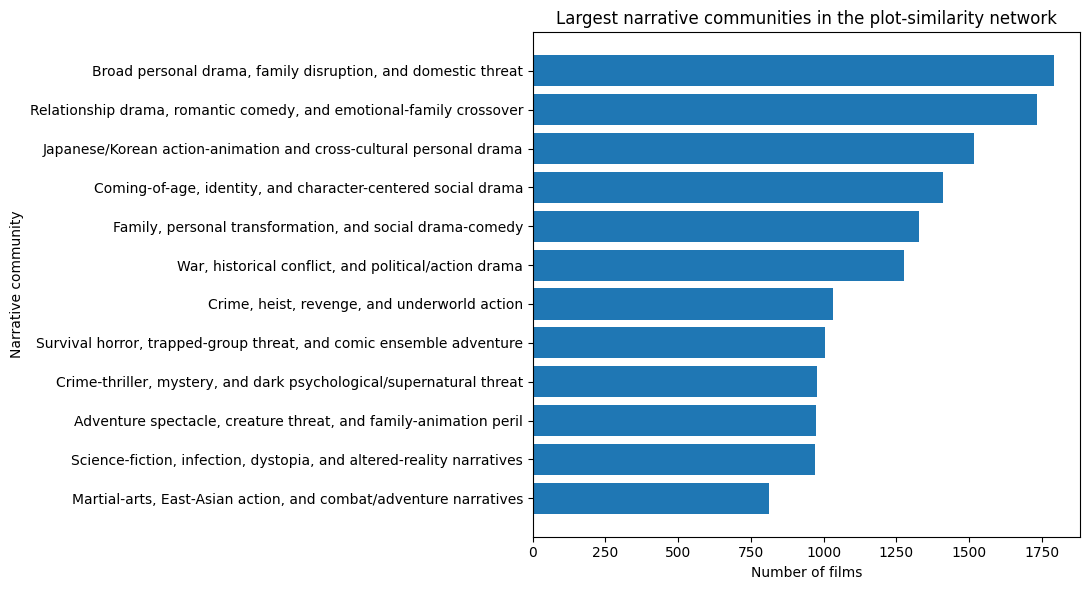

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/final_story_figures/final_major_communities_size_bar.png


In [10]:
plot_df = final_major_communities.head(12).copy()

plt.figure(figsize=(11, 6))
plt.barh(
    plot_df["narrative_label"].astype(str)[::-1],
    plot_df["size"][::-1]
)
plt.xlabel("Number of films")
plt.ylabel("Narrative community")
plt.title("Largest narrative communities in the plot-similarity network")
plt.tight_layout()

fig_path = FINAL_FIGURES_DIR / "final_major_communities_size_bar.png"
plt.savefig(fig_path, dpi=220)
plt.show()

print("Saved:", fig_path)

## 9. Central examples inside communities

These are better for the audience than one global centrality list.

They answer:

> What movies are typical examples of each narrative neighborhood?


In [11]:
central_cols = [
    "community_id", "rank_within_community", "title", "release_year",
    "primary_genre", "vote_count", "vote_average", "weighted_degree",
    "betweenness_centrality_sampled", "pagerank"
]

central_available = [c for c in central_cols if c in top_visible_central.columns]
central_examples = top_visible_central[central_available].copy()

# Merge manual labels
label_lookup = community_labels[["community_id", "suggested_label_manual"]].drop_duplicates()
central_examples = central_examples.merge(label_lookup, on="community_id", how="left")

central_examples = central_examples.rename(columns={
    "suggested_label_manual": "narrative_label",
    "rank_within_community": "rank"
})

central_examples = central_examples.sort_values(["community_id", "rank"]).reset_index(drop=True)

# Main text: top 1 central visible example per major community
central_examples_top1 = central_examples[central_examples["rank"] == 1].copy()
central_examples_top1 = central_examples_top1.merge(
    final_major_communities[["community_id", "size"]],
    on="community_id",
    how="left"
).sort_values("size", ascending=False)

display(central_examples_top1.head(15))

central_examples.to_csv(
    FINAL_TABLES_DIR / "final_central_examples_by_community_full.csv",
    index=False
)

central_examples_top1.to_csv(
    FINAL_TABLES_DIR / "final_central_examples_by_community_main.csv",
    index=False
)

print("Saved full:", FINAL_TABLES_DIR / "final_central_examples_by_community_full.csv")
print("Saved main:", FINAL_TABLES_DIR / "final_central_examples_by_community_main.csv")

,community_id,rank,title,release_year,primary_genre,vote_count,vote_average,weighted_degree,betweenness_centrality_sampled,pagerank,narrative_label,size
14,14,1,The Kindred,2021,Horror,125.0,6.400,13.124843,0.000343,0.000090,"Broad personal drama, family disruption, and domestic threat",1792.0
22,22,1,Amer,2009,Thriller,169.0,6.200,13.117239,0.000102,0.000094,"Relationship drama, romantic comedy, and emotional-family crossover",1735.0
12,12,1,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond,2019,Animation,244.0,7.900,12.368310,0.000250,0.000097,Japanese/Korean action-animation and cross-cultural personal drama,1517.0
2,2,1,Amanda,2018,Drama,295.0,7.100,12.291271,0.000386,0.000096,"Coming-of-age, identity, and character-centered social drama",1411.0
24,24,1,What's in a Name,2012,Comedy,1785.0,7.324,12.318425,0.000148,0.000090,"Family, personal transformation, and social drama-comedy",1327.0
4,4,1,Sobibor,2018,War,325.0,6.600,11.814263,0.000364,0.000095,"War, historical conflict, and political/action drama",1276.0
23,23,1,7 Minutes,2014,Crime,127.0,5.300,12.050929,0.000220,0.000093,"Crime, heist, revenge, and underworld action",1031.0
8,8,1,Haunt,2019,Horror,1353.0,6.700,12.886360,0.000122,0.000094,"Survival horror, trapped-group threat, and comic ensemble adventure",1005.0
25,25,1,Crescent City,2024,Crime,73.0,6.000,13.036527,0.000225,0.000090,"Crime-thriller, mystery, and dark psychological/supernatural threat",977.0
10,10,1,Shark Attack 3: Megalodon,2002,Horror,146.0,4.700,11.937957,0.000061,0.000084,"Adventure spectacle, creature threat, and family-animation peril",974.0


Saved full: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_central_examples_by_community_full.csv
Saved main: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_central_examples_by_community_main.csv


## 10. Bridging examples

Bridging examples are films with high betweenness.

They should be described as films that may connect narrative neighborhoods, not as “better” films.


In [12]:
bridge_cols = [
    "title", "release_year", "primary_genre", "vote_count", "vote_average",
    "community_id", "degree", "weighted_degree", "pagerank",
    "betweenness_centrality_sampled"
]

bridge_available = [c for c in bridge_cols if c in top_betweenness_visible.columns]
bridging_examples = top_betweenness_visible[bridge_available].copy()

bridging_examples = bridging_examples.merge(
    label_lookup,
    on="community_id",
    how="left"
).rename(columns={"suggested_label_manual": "narrative_label"})

bridging_examples_main = bridging_examples.head(15).copy()

display(bridging_examples_main)

bridging_examples.to_csv(
    FINAL_TABLES_DIR / "final_bridging_examples_full.csv",
    index=False
)

bridging_examples_main.to_csv(
    FINAL_TABLES_DIR / "final_bridging_examples_main.csv",
    index=False
)

print("Saved full:", FINAL_TABLES_DIR / "final_bridging_examples_full.csv")
print("Saved main:", FINAL_TABLES_DIR / "final_bridging_examples_main.csv")

,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,narrative_label
0,The Bandit,1996,Crime,355.0,7.300,22,18,9.672851,0.000093,0.002223,"Relationship drama, romantic comedy, and emotional-family crossover"
1,The TV Set,2007,Comedy,89.0,6.000,6,13,6.224862,0.000077,0.002018,"Identity crisis, family/home disruption, and adult-life thriller-comedy"
2,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.300,10,14,6.649705,0.000078,0.001957,"Adventure spectacle, creature threat, and family-animation peril"
3,Intacto,2001,Action,196.0,6.600,23,18,9.807808,0.000094,0.001868,"Crime, heist, revenge, and underworld action"
4,The Perfect Weapon,1991,Action,124.0,6.200,10,16,8.534136,0.000098,0.001788,"Adventure spectacle, creature threat, and family-animation peril"
5,Nightcrawler,2014,Crime,11648.0,7.709,1,16,8.254610,0.000100,0.001616,"Work, ambition, isolation, and adult-life disruption"
6,Darkland,2017,Thriller,139.0,6.200,22,15,7.945254,0.000083,0.001571,"Relationship drama, romantic comedy, and emotional-family crossover"
7,Jungle,2017,Adventure,2118.0,6.600,14,18,9.971398,0.000098,0.001569,"Broad personal drama, family disruption, and domestic threat"
8,Beethoven's Big Break,2008,Family,160.0,5.200,10,17,8.382484,0.000093,0.001551,"Adventure spectacle, creature threat, and family-animation peril"
9,Animal Kingdom,2010,Crime,900.0,6.800,2,17,8.935982,0.000091,0.001549,"Coming-of-age, identity, and character-centered social drama"


Saved full: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_bridging_examples_full.csv
Saved main: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_bridging_examples_main.csv


## 11. Central vs bridging explanation table

This table translates network metrics into audience language.


In [13]:
central_vs_bridge_explainer = pd.DataFrame([
    {
        "network_role": "Central story example",
        "metric_used": "weighted_degree",
        "plain_language_meaning": "A film located in a dense neighborhood of similar plot descriptions.",
        "thesis_use": "Use these films as typical examples of a narrative community."
    },
    {
        "network_role": "Bridging story example",
        "metric_used": "betweenness_centrality_sampled",
        "plain_language_meaning": "A film that sits between different story neighborhoods in the network.",
        "thesis_use": "Use these films to show how some narratives combine elements from different communities."
    },
    {
        "network_role": "Narrative community",
        "metric_used": "Louvain community_id",
        "plain_language_meaning": "A group of films more densely connected to each other by plot similarity.",
        "thesis_use": "Use communities as discovered narrative neighborhoods, not fixed genre labels."
    },
    {
        "network_role": "Peripheral story",
        "metric_used": "low degree / low clustering",
        "plain_language_meaning": "A film less embedded in local story neighborhoods.",
        "thesis_use": "Use cautiously as examples of less typical or less repeated narrative patterns."
    },
])

display(central_vs_bridge_explainer)

central_vs_bridge_explainer.to_csv(
    FINAL_TABLES_DIR / "final_central_vs_bridging_explainer.csv",
    index=False
)

print("Saved:", FINAL_TABLES_DIR / "final_central_vs_bridging_explainer.csv")

,network_role,metric_used,plain_language_meaning,thesis_use
0,Central story example,weighted_degree,A film located in a dense neighborhood of similar plot descriptions.,Use these films as typical examples of a narrative community.
1,Bridging story example,betweenness_centrality_sampled,A film that sits between different story neighborhoods in the network.,Use these films to show how some narratives combine elements from different communities.
2,Narrative community,Louvain community_id,A group of films more densely connected to each other by plot similarity.,"Use communities as discovered narrative neighborhoods, not fixed genre labels."
3,Peripheral story,low degree / low clustering,A film less embedded in local story neighborhoods.,Use cautiously as examples of less typical or less repeated narrative patterns.


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_central_vs_bridging_explainer.csv


## 12. Model summary table

This table summarizes Notebook 5 without overwhelming the audience with coefficient details.

It shows whether adding cast proxies and community fixed effects improves model fit.


In [14]:
# Extract one R² per outcome/model
model_summary = (
    regression_results
    .groupby(["outcome", "model"], as_index=False)
    .agg(
        n_obs=("n_obs", "max"),
        r_squared=("r_squared", "max"),
        adj_r_squared=("adj_r_squared", "max")
    )
)

# Friendly outcome labels
outcome_labels = {
    "log_revenue": "Commercial success: log revenue",
    "revenue_percentile_year": "Commercial success: revenue percentile within year",
    "vote_average": "Evaluative success: vote average",
    "log_popularity": "Audience attention: log popularity"
}

model_order = [
    "M1_network_genre_year",
    "M2_add_cast_proxy",
    "M3_add_community_FE"
]

model_summary["outcome_label"] = model_summary["outcome"].map(outcome_labels).fillna(model_summary["outcome"])
model_summary["model"] = pd.Categorical(model_summary["model"], categories=model_order, ordered=True)
model_summary = model_summary.sort_values(["outcome_label", "model"])

display(model_summary)

# Pivot for thesis
pivot_r2 = model_summary.pivot_table(
    index=["outcome", "outcome_label"],
    columns="model",
    values="r_squared",
    aggfunc="first"
).reset_index()

for c in model_order:
    if c not in pivot_r2.columns:
        pivot_r2[c] = np.nan

pivot_r2["cast_proxy_gain_M2_minus_M1"] = pivot_r2["M2_add_cast_proxy"] - pivot_r2["M1_network_genre_year"]
pivot_r2["community_gain_M3_minus_M2"] = pivot_r2["M3_add_community_FE"] - pivot_r2["M2_add_cast_proxy"]
pivot_r2["best_r_squared"] = pivot_r2[model_order].max(axis=1)

def outcome_interpretation(row):
    outcome = row["outcome"]
    if outcome == "vote_average":
        return "Ratings/evaluative reception show the strongest association with narrative-community structure."
    if outcome == "log_revenue":
        return "Revenue is associated with narrative and cast features, but commercial success remains only partly explained."
    if outcome == "revenue_percentile_year":
        return "Year-adjusted revenue shows similar modest associations, reducing direct cross-year revenue comparability issues."
    if outcome == "log_popularity":
        return "Popularity is weakly explained, suggesting attention depends strongly on factors outside the plot network."
    return "Interpret cautiously."

pivot_r2["audience_interpretation"] = pivot_r2.apply(outcome_interpretation, axis=1)

final_model_summary = pivot_r2[
    [
        "outcome_label",
        "M1_network_genre_year",
        "M2_add_cast_proxy",
        "M3_add_community_FE",
        "cast_proxy_gain_M2_minus_M1",
        "community_gain_M3_minus_M2",
        "best_r_squared",
        "audience_interpretation"
    ]
].copy()

# Round numeric columns
for col in final_model_summary.columns:
    if col != "outcome_label" and col != "audience_interpretation":
        final_model_summary[col] = final_model_summary[col].round(4)

display(final_model_summary)

model_summary.to_csv(
    FINAL_TABLES_DIR / "final_model_summary_long.csv",
    index=False
)

final_model_summary.to_csv(
    FINAL_TABLES_DIR / "final_model_summary_table.csv",
    index=False
)

print("Saved long:", FINAL_TABLES_DIR / "final_model_summary_long.csv")
print("Saved thesis table:", FINAL_TABLES_DIR / "final_model_summary_table.csv")

,outcome,model,n_obs,r_squared,adj_r_squared,outcome_label
0,log_popularity,M1_network_genre_year,19202,0.056739,0.055707,Audience attention: log popularity
1,log_popularity,M2_add_cast_proxy,19202,0.068991,0.067825,Audience attention: log popularity
2,log_popularity,M3_add_community_FE,19202,0.079918,0.077564,Audience attention: log popularity
3,log_revenue,M1_network_genre_year,7576,0.100796,0.098297,Commercial success: log revenue
4,log_revenue,M2_add_cast_proxy,7576,0.109226,0.106395,Commercial success: log revenue
5,log_revenue,M3_add_community_FE,7576,0.132984,0.127339,Commercial success: log revenue
6,revenue_percentile_year,M1_network_genre_year,7576,0.096207,0.093695,Commercial success: revenue percentile within year
7,revenue_percentile_year,M2_add_cast_proxy,7576,0.105322,0.102478,Commercial success: revenue percentile within year
8,revenue_percentile_year,M3_add_community_FE,7576,0.130781,0.125121,Commercial success: revenue percentile within year
9,vote_average,M1_network_genre_year,19202,0.152551,0.151623,Evaluative success: vote average


model,outcome_label,M1_network_genre_year,M2_add_cast_proxy,M3_add_community_FE,cast_proxy_gain_M2_minus_M1,community_gain_M3_minus_M2,best_r_squared,audience_interpretation
0,Audience attention: log popularity,0.0567,0.0690,0.0799,0.0123,0.0109,0.0799,"Popularity is weakly explained, suggesting attention depends strongly on factors outside the plot network."
1,Commercial success: log revenue,0.1008,0.1092,0.1330,0.0084,0.0238,0.1330,"Revenue is associated with narrative and cast features, but commercial success remains only partly explained."
2,Commercial success: revenue percentile within year,0.0962,0.1053,0.1308,0.0091,0.0255,0.1308,"Year-adjusted revenue shows similar modest associations, reducing direct cross-year revenue comparability issues."
3,Evaluative success: vote average,0.1526,0.1535,0.1840,0.0009,0.0305,0.1840,Ratings/evaluative reception show the strongest association with narrative-community structure.


Saved long: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_model_summary_long.csv
Saved thesis table: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_model_summary_table.csv


## 13. Figure — model fit by outcome

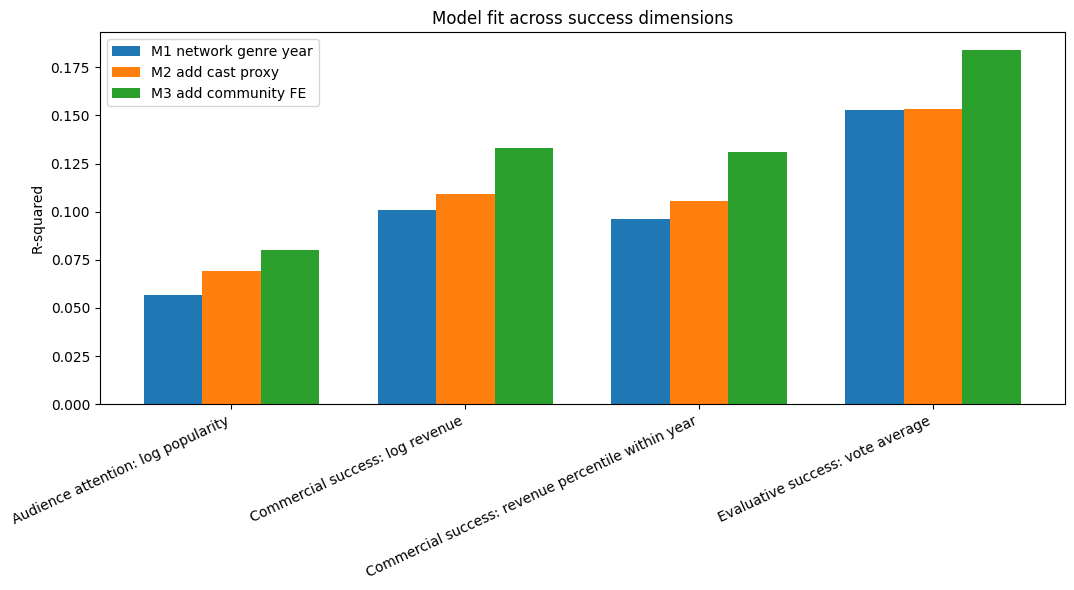

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/final_story_figures/final_model_fit_by_outcome.png


In [15]:
plot_df = model_summary.copy()

plt.figure(figsize=(11, 6))

x_labels = plot_df["outcome_label"].unique().tolist()
x = np.arange(len(x_labels))
width = 0.25

for i, model in enumerate(model_order):
    vals = []
    for outcome_label in x_labels:
        hit = plot_df[(plot_df["outcome_label"] == outcome_label) & (plot_df["model"] == model)]["r_squared"]
        vals.append(hit.iloc[0] if len(hit) else np.nan)
    plt.bar(x + (i - 1) * width, vals, width=width, label=model.replace("_", " "))

plt.xticks(x, x_labels, rotation=25, ha="right")
plt.ylabel("R-squared")
plt.title("Model fit across success dimensions")
plt.legend()
plt.tight_layout()

fig_path = FINAL_FIGURES_DIR / "final_model_fit_by_outcome.png"
plt.savefig(fig_path, dpi=220)
plt.show()

print("Saved:", fig_path)

## 14. Community success summary for audience

This table connects narrative communities to multiple success signals.

Use it descriptively. Do not claim causality.


In [16]:
community_success_final = community_success.copy()

# Ensure label column exists
if "suggested_label_manual" not in community_success_final.columns:
    community_success_final = community_success_final.merge(
        label_lookup,
        on="community_id",
        how="left"
    )

community_success_final = community_success_final.rename(columns={
    "suggested_label_manual": "narrative_label"
})

# Pick important columns if available
cols = [
    "community_id", "narrative_label", "n_films",
    "revenue_available_pct", "median_revenue_percentile_year",
    "median_vote_average", "median_vote_count",
    "median_popularity", "median_weighted_degree",
    "median_cast_size", "median_top_cast_exposure_max"
]

cols = [c for c in cols if c in community_success_final.columns]
community_success_final = community_success_final[cols].copy()

community_success_final = community_success_final.sort_values("n_films", ascending=False)

display(community_success_final.head(15))

community_success_final.to_csv(
    FINAL_TABLES_DIR / "final_community_success_summary.csv",
    index=False
)

print("Saved:", FINAL_TABLES_DIR / "final_community_success_summary.csv")

,community_id,narrative_label,n_films,revenue_available_pct,median_revenue_percentile_year,median_vote_average,median_vote_count,median_popularity,median_weighted_degree,median_cast_size,median_top_cast_exposure_max
0,14,"Broad personal drama, family disruption, and domestic threat",1792,36.38,0.402694,6.100,82.0,1.52975,4.870969,5.0,3.0
1,22,"Relationship drama, romantic comedy, and emotional-family crossover",1735,32.16,0.355916,6.300,79.0,1.27090,4.393519,5.0,3.0
2,12,Japanese/Korean action-animation and cross-cultural personal drama,1517,34.15,0.466799,6.600,61.0,1.68390,4.047611,5.0,4.0
3,2,"Coming-of-age, identity, and character-centered social drama",1411,41.11,0.459030,6.000,102.0,1.57790,4.501107,5.0,3.0
4,24,"Family, personal transformation, and social drama-comedy",1327,34.97,0.423798,6.100,99.0,1.39780,4.285003,5.0,4.0
5,4,"War, historical conflict, and political/action drama",1276,40.44,0.456949,6.279,86.5,1.47260,4.194384,5.0,3.0
6,23,"Crime, heist, revenge, and underworld action",1031,45.68,0.537815,6.100,123.0,1.87860,4.058141,5.0,4.0
7,8,"Survival horror, trapped-group threat, and comic ensemble adventure",1005,36.42,0.493628,5.800,100.0,1.56170,4.957902,5.0,3.0
8,25,"Crime-thriller, mystery, and dark psychological/supernatural threat",977,33.57,0.446681,6.000,87.0,1.51200,4.472257,5.0,3.0
9,10,"Adventure spectacle, creature threat, and family-animation peril",974,48.05,0.624185,6.100,128.5,1.89800,4.022564,5.0,4.0


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_community_success_summary.csv


## 15. Figure — success dimensions by community

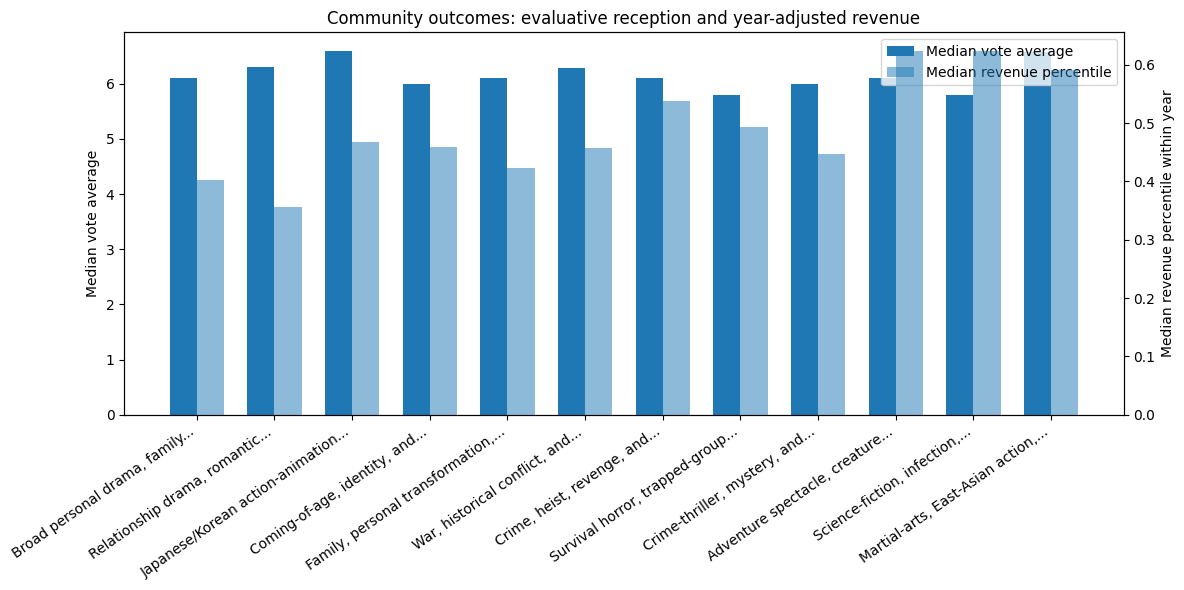

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/final_story_figures/final_community_success_dimensions.png


In [17]:
# Plot top 12 communities by size using vote average and revenue percentile if available
plot_df = community_success_final.head(12).copy()

if "median_revenue_percentile_year" in plot_df.columns and "median_vote_average" in plot_df.columns:
    labels = plot_df["narrative_label"].astype(str).apply(lambda x: textwrap.shorten(x, width=35, placeholder="..."))

    fig, ax1 = plt.subplots(figsize=(12, 6))

    x = np.arange(len(plot_df))
    width = 0.35

    ax1.bar(x - width/2, plot_df["median_vote_average"], width=width, label="Median vote average")
    ax1.set_ylabel("Median vote average")

    ax2 = ax1.twinx()
    ax2.bar(x + width/2, plot_df["median_revenue_percentile_year"], width=width, alpha=0.5, label="Median revenue percentile")
    ax2.set_ylabel("Median revenue percentile within year")

    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, rotation=35, ha="right")
    ax1.set_title("Community outcomes: evaluative reception and year-adjusted revenue")

    # combine legends
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

    plt.tight_layout()

    fig_path = FINAL_FIGURES_DIR / "final_community_success_dimensions.png"
    plt.savefig(fig_path, dpi=220)
    plt.show()

    print("Saved:", fig_path)
else:
    print("Required columns not available for this plot.")

## 16. Pipeline diagram

This figure explains the whole thesis in one visual.

Use it in the methodology or presentation.


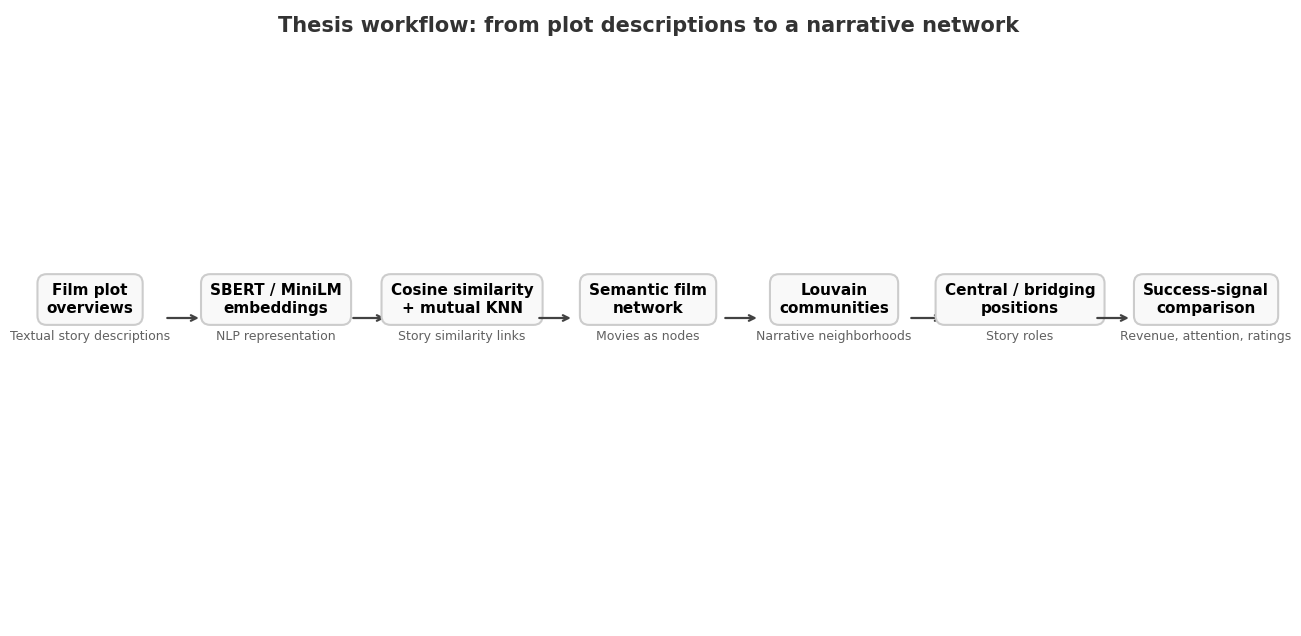

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/final_story_figures/final_thesis_pipeline_diagram_horizontal.png


In [28]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(16, 8))
ax.axis("off")

steps = [
    ("Film plot\noverviews", "Textual story descriptions"),
    ("SBERT / MiniLM\nembeddings", "NLP representation"),
    ("Cosine similarity\n+ mutual KNN", "Story similarity links"),
    ("Semantic film\nnetwork", "Movies as nodes"),
    ("Louvain\ncommunities", "Narrative neighborhoods"),
    ("Central / bridging\npositions", "Story roles"),
    ("Success-signal\ncomparison", "Revenue, attention, ratings")
]

x_positions = np.linspace(0.05, 0.95, len(steps))

for i, ((title, subtitle), x_pos) in enumerate(zip(steps, x_positions)):
    ax.text(
        x_pos, 0.53, title,
        ha="center", va="center",
        fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.6", fc="#f9f9f9", ec="#cccccc", lw=1.5)
    )
    ax.text(
        x_pos, 0.47, subtitle,
        ha="center", va="center",
        fontsize=9, color="#616161"
    )

    if i < len(steps) - 1:
        # Ensure arrow points from current step (i) to next step (i+1)
        ax.annotate(
            "",
            xy=(x_positions[i+1] - 0.06, 0.5),   # Arrow tip (Next Box)
            xytext=(x_positions[i] + 0.06, 0.5), # Arrow base (Current Box)
            arrowprops=dict(arrowstyle="->", lw=1.6, color="#424242")
        )

ax.set_title("Thesis workflow: from plot descriptions to a narrative network", fontsize=15, fontweight="bold", color="#333333", y=0.95)

fig_path = FINAL_FIGURES_DIR / "final_thesis_pipeline_diagram_horizontal.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 17. Final thesis narrative text

This file gives ready-to-edit writing for the results section.

Use it as a draft, not as final copy.


In [ ]:
final_results_narrative = f'''
FINAL RESULTS NARRATIVE — READY-TO-EDIT DRAFT

1. Main idea

This thesis represents films as a plot-based semantic network. Instead of connecting movies because they share actors, directors, or predefined genres, movies are connected when their plot descriptions are semantically similar. This makes it possible to study cinema as a network of stories.

2. Network construction result

The final semantic network contains {n_nodes:,} films and {n_edges:,} mutual-KNN plot-similarity links. The films cover the period {min_year}–{max_year}. Community detection identifies {n_communities} total narrative communities, of which {n_major_communities} larger communities are manually interpreted in the thesis.

3. Narrative communities

The discovered communities should not be interpreted as strict genres. Instead, they represent recurring narrative neighborhoods in the plot-description space. For example, some communities concentrate around relationship drama and social comedy, while others concentrate around war and historical conflict, crime and revenge narratives, science-fiction or dystopian narratives, holiday/family narratives, or superhero and mythic adventure structures.

4. Central and bridging films

Central films are interpreted as typical examples of dense narrative neighborhoods. Bridging films are interpreted as films that may connect different story regions. These roles are structural positions in the network, not rankings of quality, fame, or box-office performance.

5. Success as multi-dimensional

Success is treated as more than box office. The thesis distinguishes commercial success, audience attention, and evaluative reception. Commercial success is measured using revenue and revenue percentile within release year. Audience attention is proxied using vote count and popularity. Evaluative reception is proxied using vote average. Awards and formal recognition are discussed conceptually but are not modeled because structured awards data are not included in the current dataset.

6. Outcome-association result

The outcome models suggest that narrative-network features and community membership are associated with success signals, but the strength of association differs by outcome. The strongest model fit appears for evaluative reception, while revenue and popularity are more weakly explained. This supports the interpretation that plot-based narrative structure is especially useful for understanding story neighborhoods and evaluative patterns, while commercial success depends strongly on additional factors such as marketing, distribution, release scale, franchise strategy, and platform attention.

7. Main contribution

The main contribution is not a box-office prediction model. The main contribution is a plot-based network approach for mapping film relationships. The thesis shows that NLP-based plot similarity can reveal narrative communities and structural positions that are not visible when films are grouped only by actors, genres, or popularity.
'''.strip()

narrative_path = FINAL_TABLES_DIR / "final_results_narrative_draft.txt"
narrative_path.write_text(final_results_narrative, encoding="utf-8")

print(final_results_narrative)
print("\nSaved:", narrative_path)

FINAL RESULTS NARRATIVE — READY-TO-EDIT DRAFT

1. Main idea

This thesis represents films as a plot-based semantic network. Instead of connecting movies because they share actors, directors, or predefined genres, movies are connected when their plot descriptions are semantically similar. This makes it possible to study cinema as a network of stories.

2. Network construction result

The final semantic network contains 19,202 films and 86,685 mutual-KNN plot-similarity links. The films cover the period 1990–2024. Community detection identifies 26 total narrative communities, of which 23 larger communities are manually interpreted in the thesis.

3. Narrative communities

The discovered communities should not be interpreted as strict genres. Instead, they represent recurring narrative neighborhoods in the plot-description space. For example, some communities concentrate around relationship drama and social comedy, while others concentrate around war and historical conflict, crime and rev

## 18. Final presentation storyboard

This gives the order for thesis slides or a results chapter.


In [ ]:
storyboard = pd.DataFrame([
    {
        "order": 1,
        "section": "The problem",
        "main_message": "Movies are often grouped by actors, genres, or revenue, but they can also be connected by story similarity.",
        "recommended_output": "Short explanation / motivation slide"
    },
    {
        "order": 2,
        "section": "The method",
        "main_message": "Plot descriptions are converted into semantic vectors and used to build a mutual-KNN similarity network.",
        "recommended_output": "final_thesis_pipeline_diagram.png"
    },
    {
        "order": 3,
        "section": "The map",
        "main_message": "The final network contains thousands of films and story-similarity links.",
        "recommended_output": "final_network_summary_table.csv"
    },
    {
        "order": 4,
        "section": "The neighborhoods",
        "main_message": "The network reveals major narrative communities, interpreted as story neighborhoods rather than strict genres.",
        "recommended_output": "final_major_communities_table_main_text.csv and final_major_communities_size_bar.png"
    },
    {
        "order": 5,
        "section": "The roles",
        "main_message": "Central films are typical examples of a narrative neighborhood; bridging films connect different neighborhoods.",
        "recommended_output": "final_central_examples_by_community_main.csv and final_bridging_examples_main.csv"
    },
    {
        "order": 6,
        "section": "Success is multidimensional",
        "main_message": "The thesis treats success as commercial performance, audience attention, and evaluative reception.",
        "recommended_output": "final_success_dimensions_table.csv"
    },
    {
        "order": 7,
        "section": "Outcome associations",
        "main_message": "Narrative-network features relate more clearly to evaluative reception than to revenue or popularity.",
        "recommended_output": "final_model_summary_table.csv and final_model_fit_by_outcome.png"
    },
    {
        "order": 8,
        "section": "Conclusion",
        "main_message": "A plot-based network offers a new way to map film relationships beyond actors, genres, and box office.",
        "recommended_output": "final_results_narrative_draft.txt"
    },
])

display(storyboard)

storyboard.to_csv(
    FINAL_TABLES_DIR / "final_presentation_storyboard.csv",
    index=False
)

print("Saved:", FINAL_TABLES_DIR / "final_presentation_storyboard.csv")

,order,section,main_message,recommended_output
0,1,The problem,"Movies are often grouped by actors, genres, or revenue, but they can also be connected by story similarity.",Short explanation / motivation slide
1,2,The method,Plot descriptions are converted into semantic vectors and used to build a mutual-KNN similarity network.,final_thesis_pipeline_diagram.png
2,3,The map,The final network contains thousands of films and story-similarity links.,final_network_summary_table.csv
3,4,The neighborhoods,"The network reveals major narrative communities, interpreted as story neighborhoods rather than strict genres.",final_major_communities_table_main_text.csv and final_major_communities_size_bar.png
4,5,The roles,Central films are typical examples of a narrative neighborhood; bridging films connect different neighborhoods.,final_central_examples_by_community_main.csv and final_bridging_examples_main.csv
5,6,Success is multidimensional,"The thesis treats success as commercial performance, audience attention, and evaluative reception.",final_success_dimensions_table.csv
6,7,Outcome associations,Narrative-network features relate more clearly to evaluative reception than to revenue or popularity.,final_model_summary_table.csv and final_model_fit_by_outcome.png
7,8,Conclusion,"A plot-based network offers a new way to map film relationships beyond actors, genres, and box office.",final_results_narrative_draft.txt


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_presentation_storyboard.csv


## 19. Final output list

In [ ]:
outputs = [
    FINAL_TABLES_DIR / "final_network_summary_table.csv",
    FINAL_TABLES_DIR / "final_success_dimensions_table.csv",
    FINAL_TABLES_DIR / "final_major_communities_table_full.csv",
    FINAL_TABLES_DIR / "final_major_communities_table_main_text.csv",
    FINAL_TABLES_DIR / "final_central_examples_by_community_full.csv",
    FINAL_TABLES_DIR / "final_central_examples_by_community_main.csv",
    FINAL_TABLES_DIR / "final_bridging_examples_full.csv",
    FINAL_TABLES_DIR / "final_bridging_examples_main.csv",
    FINAL_TABLES_DIR / "final_central_vs_bridging_explainer.csv",
    FINAL_TABLES_DIR / "final_model_summary_long.csv",
    FINAL_TABLES_DIR / "final_model_summary_table.csv",
    FINAL_TABLES_DIR / "final_community_success_summary.csv",
    FINAL_TABLES_DIR / "final_results_narrative_draft.txt",
    FINAL_TABLES_DIR / "final_presentation_storyboard.csv",
    FINAL_FIGURES_DIR / "final_major_communities_size_bar.png",
    FINAL_FIGURES_DIR / "final_model_fit_by_outcome.png",
    FINAL_FIGURES_DIR / "final_community_success_dimensions.png",
    FINAL_FIGURES_DIR / "final_thesis_pipeline_diagram.png",
]

print("Final outputs:")
for p in outputs:
    print(p.exists(), "-", p)

Final outputs:
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_network_summary_table.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_success_dimensions_table.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_major_communities_table_full.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_major_communities_table_main_text.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_central_examples_by_community_full.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_central_examples_by_community_main.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_bridging_examples_full.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_bridging_examples_main.csv

## 20. What comes after this notebook

After this notebook, you should **not** keep expanding the analysis randomly.

Next steps:

1. Use the generated final tables and figures to write the Results chapter.
2. If time allows, create a short `07_robustness_checks.ipynb`.
3. Use robustness checks as appendix/supporting evidence, not as the main story.

The main story is now:

> A plot-based semantic network reveals narrative communities and structural roles in cinema, and these narrative structures are related to different success signals in different ways.
